## **US31: Statistical Analysis on Cargo**

### **User Story Details**

As a Player, using the same data file as in the previous Sprint (Sprint 2), I want to perform a statistical analysis to determine which type of cargo contributes most significantly to the revenue of a given station, in a specific year, both defined by the user. The goal for the specified station/year is to identify the cargo (independent variable) that shows the highest correlation with revenue (dependent variable). Based on the selected cargo, a linear regression model should be aplied, presenting the error associated with the respective fit. Assuming the amount of cargo increased by 10% in January of the following year, estimate the expected revenue for January with a 95% confidence level.
    
### **Theoretical Explanation**

#### What is a Linear Regression?

Linear regression is a statistical method used to model and analyze the relationship between two or more variables. Linear regression seeks to fit a straight line through a cloud of data points in a way that the overall distance between the points and the line is minimized.

#### What is the Pearson Correlation?

Measures the linear association between X and Y using the following formula:

\begin{equation}
r = \frac{\sum_{i=1}^n (X_i - \bar X)\,(Y_i - \bar Y)}
         {\sqrt{\sum_{i=1}^n (X_i - \bar X)^2}\;\sqrt{\sum_{i=1}^n (Y_i - \bar Y)^2}}.
\end{equation}

The hypothesis test as this format:

\begin{equation}
H_0: \rho = 0
\quad\text{and}\quad
H_1: \rho \neq 0
\end{equation}

#### Prediction & 95 % Confidence Interval

We are able to calculate the average of the a certain cargo (x) for January of next year:

\begin{equation}
bar X_{\text{Jan}}
= \frac{1}{m}\sum_{i:\,\text{month}_i=1} X_i
\end{equation}

#### Increase of 10%

Assuming an increase of 10%, we can calculate it by using:

\begin{equation}
X^* = 1.10 \;\times\; \bar X_{\text{Jan}}
\end{equation}


### **Code for US31**

Available Stations:
1. Berlin
2. Frankfurt
3. Hamburg
4. Hannover
5. Stuttgart



Enter station name:  Frankfurt



Available years for 'Frankfurt': 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024


Enter year:  2021



Cargo with highest correlation: coal
Prediction for January 2022 (10% increase): 605.02
95% Confidence Interval: (414.72, 795.33)


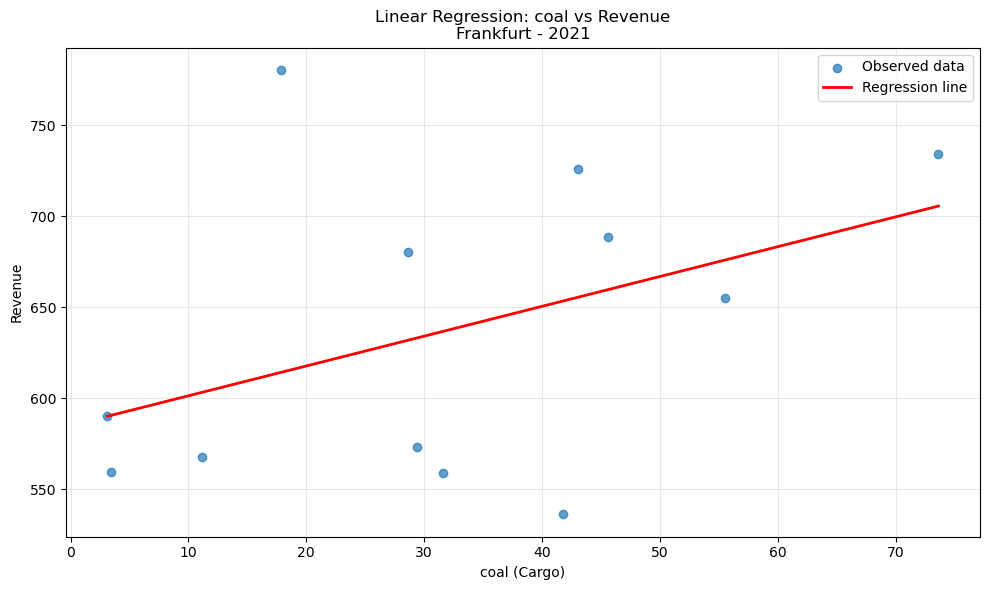

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv('Stations_Data.csv', sep=';')
df.columns = df.columns.str.strip().str.lower()
df.rename(columns={'revenues': 'revenue'}, inplace=True)

non_num = ['station', 'year', 'month']
for col in df.columns:
    if col not in non_num:
        df[col] = df[col].astype(str).str.replace(',', '.', regex=False)
        df[col] = pd.to_numeric(df[col], errors='coerce')

df['station'] = df['station'].str.strip()

print("Available Stations:")
all_stations = sorted(df['station'].unique())
for i, station_name in enumerate(all_stations, 1):
    print(f"{i}. {station_name}")

def get_valid_inputs():
    while True:
        station = input("\nEnter station name: ").strip()
        if station not in df['station'].values:
            print(f"Error: Station '{station}' not found.")
            continue
        
        available_years = sorted(df[df['station'] == station]['year'].unique())
        print(f"\nAvailable years for '{station}': {', '.join(map(str, available_years))}")
        
        try:
            year = int(input("Enter year: "))
        except ValueError:
            print("Error: Please enter a valid year.")
            continue
        
        if year not in available_years:
            print(f"Error: Year {year} not available for station '{station}'.")
            continue
        
        return station, year

station, year = get_valid_inputs()

data = df[(df['station'] == station) & (df['year'] == year)].copy()

if data.empty:
    print(f"No data found for station '{station}' in year {year}.")
else:
    exclude = ['station', 'year', 'month', 'revenue', 'expenses']
    cargo_columns = [col for col in data.columns if col not in exclude]

    correlations = {}
    for cargo in cargo_columns:
        vals = data[[cargo, 'revenue']].dropna()
        if len(vals) >= 2:
            r, _ = stats.pearsonr(vals[cargo], vals['revenue'])
            correlations[cargo] = r
    
    if not correlations:
        print("No valid cargo columns for correlation analysis.")
    else:
        best_cargo = max(correlations, key=correlations.get)
        r_best = correlations[best_cargo]

        x = data[best_cargo].values
        y = data['revenue'].values
        slope, intercept, r_value, p_value, stderr = stats.linregress(x, y)
        y_pred = intercept + slope * x

        n = len(x)
        residuals = y - y_pred
        s2 = np.sum(residuals**2) / (n - 2)
        Sxx = np.sum((x - x.mean())**2)
        t_val = stats.t.ppf(0.975, df=n - 2)

        data_jan = data[data['month'] == 1]
        if data_jan.empty:
            print(f"No January data available for year {year}.")
        else:
            jan_avg = data_jan[best_cargo].mean()
            xp = jan_avg * 1.10  
            yp = intercept + slope * xp
            interval = t_val * np.sqrt(s2 * (1 + 1/n + ((xp - x.mean())**2 / Sxx)))
            print(f"\nCargo with highest correlation: {best_cargo}")
            print(f"Prediction for January {year+1} (10% increase): {yp:.2f}")
            print(f"95% Confidence Interval: ({yp - interval:.2f}, {yp + interval:.2f})")
            
            plt.figure(figsize=(10, 6))
            sorted_idx = np.argsort(x)
            plt.scatter(x, y, alpha=0.7, label='Observed data')
            plt.plot(x[sorted_idx], y_pred[sorted_idx], 'r-', label='Regression line', linewidth=2)
            plt.xlabel(f'{best_cargo} (Cargo)')
            plt.ylabel('Revenue')
            plt.title(f'Linear Regression: {best_cargo} vs Revenue\n{station} - {year}')
            plt.legend()
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()

### **Interpretation of the obtained results**

In Frankfurt, during the year of 2021, coal is the cargo that remains on top. Using the Pearson correlation, we estimate a value of nearly 0.42, which indicates a moderate positive relationship between the coal throughput and the station income. By projecting a 10% increase on coal in January of 2022 (based on the January 2021 average), the revenue forecast seems to be around 605. The 95% confidence interval for this prediction is between [415,795]. Finally, by analyzing all the data we gathered until now, the results hint that the coal volume may lead to an increase of revenue to a certain extent, but the more data we have, the more accurate and additional predictons we are able to make. 